In [101]:
import sys

import ROOT
import numpy as np
import matplotlib.pylab as plt
import tqdm
%matplotlib inline

sys.path.append("../../../python")
from simhelper import util, root, parser
from simhelper import datatypes
from simhelper import helper_basic as hp
from simhelper import helper_plt as hplt

In [102]:
!ls $filename_digi -ltrh

-rw-r-----+ 1 tomren nogroup 31M Feb  5  2026 /project/6075887/MATHUSLA/simulation//cosmic/cosmic_all/run_177_digi.root


In [137]:
sim_data_dir = "/project/6075887/MATHUSLA/simulation/"

ifile = 550

# Check simulation raw file
filename_raw = f"{sim_data_dir}/cosmic/cosmic_all/run_{ifile}.root"
filename_digi = f"{sim_data_dir}/cosmic/cosmic_all/run_{ifile}_digi.root"
filename_recon = f"{sim_data_dir}/cosmic/cosmic_all/run_{ifile}_digi_recon.root"
print(filename_digi)

tfile_raw=ROOT.TFile(filename_raw)
tfile_digi=ROOT.TFile(filename_digi)

file_raw = root.tfile_reader(filename_raw)
file_digi = root.tfile_reader(filename_digi)
file_recon = root.tfile_reader(filename_recon)

/project/6075887/MATHUSLA/simulation//cosmic/cosmic_all/run_550_digi.root


In [138]:
# tree = tfile_raw.Get("metadata")
# tree.GetEntry(0)
# tree.Generator.as_string()

In [139]:
# Get metadata
# file_digi.get_tree("metadata_digi")
file_recon.get_tree("metadata_digi")
metadata_recon = file_recon.get_entry(0)

tree_raw = file_raw.get_tree("data")
tree_digi = file_digi.get_tree("data")
tree_recon = file_recon.get_tree("data")


entries = file_raw.entries

print("Entries raw", entries)
print("Entries digi", file_digi.entries)

Entries raw 219259
Entries digi 219259


In [140]:
root_data = file_raw.get_entry(i)
root_data.keys()

dict_keys(['Run_number', 'Evt_number', 'Seed_0', 'Seed_1', 'Hit_x', 'Hit_y', 'Hit_z', 'Hit_t', 'Hit_edep', 'Hit_px', 'Hit_py', 'Hit_pz', 'Hit_trackID', 'Hit_trackIDparent', 'Hit_pdgID', 'Hit_pdgIDparent', 'Hit_isprimary', 'Hit_processID', 'Hit_detectorID', 'Gen_x', 'Gen_y', 'Gen_z', 'Gen_t', 'Gen_px', 'Gen_py', 'Gen_pz', 'Gen_pdgID', 'Gen_index', 'Step_x', 'Step_y', 'Step_z', 'Step_t', 'Step_edep', 'Step_px', 'Step_py', 'Step_pz', 'Step_trackID', 'Step_trackIDparent', 'Step_pdgID', 'Step_status'])

In [141]:
# i=7
# root_data = file_raw.get_entry(i)
# print(root_data["Hit_pdgID"])
# print(root_data["Hit_trackID"])
# print(root_data["Hit_detectorID"])
# print(root_data["Hit_edep"])
# print(root_data["Hit_t"])

# root_data = file_digi.get_entry(i)
# print(root_data["Digi_pdgID"])
# print(root_data["Digi_type"])



In [142]:
ids = []
nhits = []
for i in tqdm.tqdm(range(entries)):
    root_data = file_digi.get_entry(i)
    # nhits.extend(root_data["Digi_pdgID"])
    # nhits.append(len(root_data["Hit_x"]))
    nhits.append(len(root_data["Digi_x"]))
    if len(root_data["Digi_x"])>5:
        ids.append(i)
print("Events with more than 5 hits:", len(ids))
print("Examples:", ids[:10])

100%|██████████| 219259/219259 [00:06<00:00, 35374.12it/s]


Events with more than 5 hits: 161005
Examples: [0, 2, 3, 4, 5, 6, 9, 10, 11, 12]


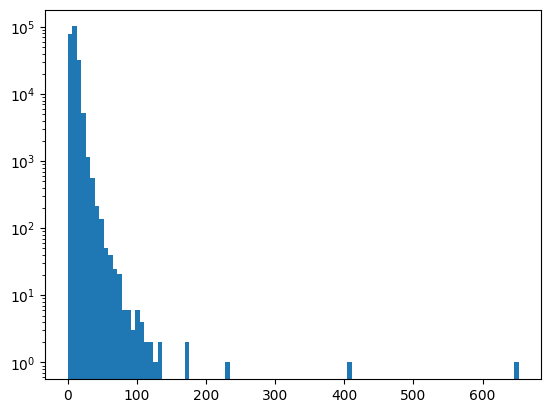

In [143]:
plt.hist(nhits, bins=100,log=1);

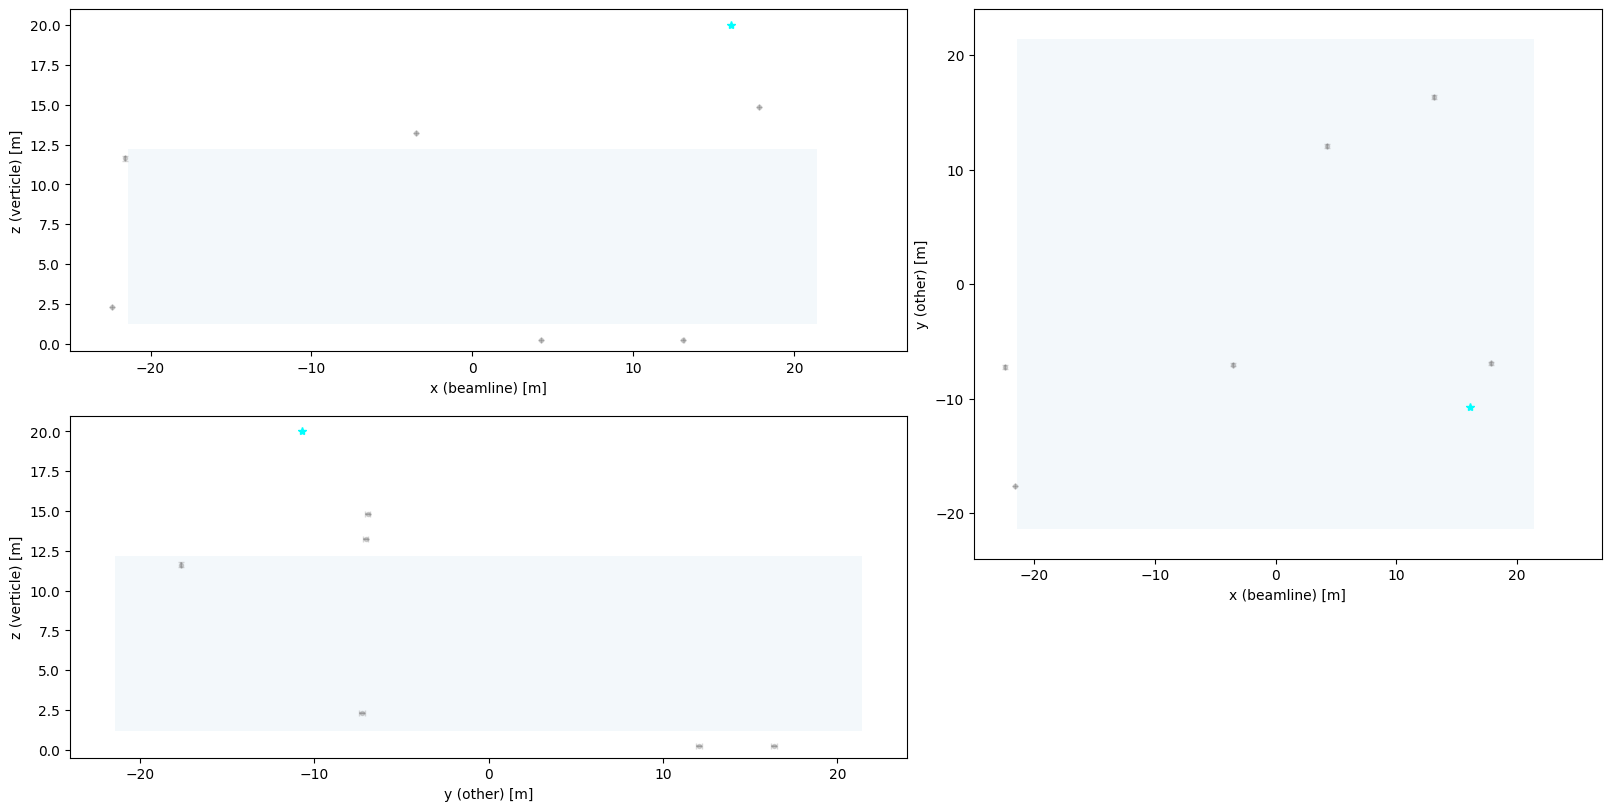

In [129]:
i=ids[0]

data_raw = file_raw.get_entry(i)
data = file_recon.get_entry(i)
event = datatypes.Event(data, metadata_recon)  
event.plot()